In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set(style="whitegrid")
pd.set_option("display.max_columns", 50)
red = pd.read_csv("winequality-red.csv", sep=";")
white = pd.read_csv("winequality-white.csv", sep=";")

red["wine_type"] = "red"
white["wine_type"] = "white"

data = pd.concat([red, white], ignore_index=True)
print("Форма данных:", data.shape)
data.head()

In [ ]:
data.info()
print("\nПропуски по столбцам:")
print(data.isna().sum())
print("\nОписательные статистики:")
data.describe().T

In [ ]:
plt.figure(figsize=(8,4))
sns.countplot(x="quality", data=data, hue="wine_type")
plt.title("Распределение качества вина")
plt.show()

print("Доли классов:")
print(data["quality"].value_counts(normalize=True).sort_index().round(4))

Классы сильно несбалансированы. Большинство вин имеют качество 5–7, а 3, 4, 8, 9 встречаются редко. Из-за этого модель будет хуже предсказывать редкие значения — их мало в обучении.

In [ ]:
numeric_cols = data.select_dtypes(include=np.number).columns
corr_with_target = data[numeric_cols].corr()["quality"].sort_values(ascending=False)
print(corr_with_target)

plt.figure(figsize=(6,8))
corr_with_target.drop("quality").plot(kind="barh", color="steelblue")
plt.title("Корреляция признаков с quality")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

Сильнее всего с качеством связаны alcohol (положительно, ~0.44) и volatile acidity (отрицательно, ~ -0.27). Это логично: крепкие вина оценивают выше, а вина с высокой летучей кислотностью — ниже. 

In [ ]:
data[numeric_cols].hist(figsize=(14,10), bins=30)
plt.tight_layout()
plt.show()


In [ ]:
X = data.drop(columns=["quality", "wine_type"])
y = data["quality"]

X["is_red"] = (data["wine_type"] == "red").astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, shuffle=True
)

print("Train:", X_train.shape, "Test:", X_test.shape)

baseline: 

In [59]:
baseline_value = y_train.mean()
baseline_pred = np.full(shape=len(y_test), fill_value=baseline_value)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print(f"Baseline (mean={baseline_value:.3f}): RMSE={baseline_rmse:.4f}, MAE={baseline_mae:.4f}")

Baseline (mean=5.815): RMSE=0.8596, MAE=0.6691


линейная регрессия: 

In [60]:
lin_model = make_pipeline(StandardScaler(), LinearRegression())
lin_model.fit(X_train, y_train)
lin_pred = lin_model.predict(X_test)

lin_rmse = np.sqrt(mean_squared_error(y_test, lin_pred))
lin_mae = mean_absolute_error(y_test, lin_pred)
print(f"Linear Regression: RMSE={lin_rmse:.4f}, MAE={lin_mae:.4f}")

coefs = pd.Series(
    lin_model.named_steps["linearregression"].coef_,
    index=X_train.columns
).sort_values(key=np.abs, ascending=False)
print("\nКоэффициенты (после стандартизации):")
print(coefs)

Linear Regression: RMSE=0.7357, MAE=0.5644

Коэффициенты (после стандартизации):
density                -0.307099
residual sugar          0.301300
alcohol                 0.277079
volatile acidity       -0.244675
is_red                  0.143580
fixed acidity           0.118681
sulphates               0.113420
free sulfur dioxide     0.104242
total sulfur dioxide   -0.091639
pH                      0.084217
chlorides              -0.020291
citric acid            -0.014161
dtype: float64


Линейная регрессия даёт RMSE ≈ 0.73 — уже лучше baseline. После стандартизации видно, что сильнее всего влияют alcohol (плюс) и volatile acidity (минус). Но RMSE всё ещё выше 0.70, значит линейной модели не хватает — связи в данных нелинейные.

Random Forest:

In [61]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    min_samples_leaf=2,
    random_state=RANDOM_STATE,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_mae = mean_absolute_error(y_test, rf_pred)
print(f"Random Forest: RMSE={rf_rmse:.4f}, MAE={rf_mae:.4f}")

rf_importance = pd.Series(rf_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nFeature importance (RF):")
print(rf_importance)

Random Forest: RMSE=0.6157, MAE=0.4489

Feature importance (RF):
alcohol                 0.268500
volatile acidity        0.133259
free sulfur dioxide     0.087561
sulphates               0.076710
total sulfur dioxide    0.069724
residual sugar          0.067957
pH                      0.067290
chlorides               0.061238
citric acid             0.057282
density                 0.056248
fixed acidity           0.053517
is_red                  0.000714
dtype: float64


Random Forest даёт RMSE ≈ 0.62 — сильно лучше линейной регрессии. Деревья ловят нелинейности и взаимодействия признаков. В feature importance наверху тоже alcohol, volatile acidity, плюс is_red и density — совпадает с EDA

Gradient Boosting:

In [62]:
gb_model = GradientBoostingRegressor(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=3,
    random_state=RANDOM_STATE
)
gb_model.fit(X_train, y_train)
gb_pred = gb_model.predict(X_test)

gb_rmse = np.sqrt(mean_squared_error(y_test, gb_pred))
gb_mae = mean_absolute_error(y_test, gb_pred)
print(f"Gradient Boosting: RMSE={gb_rmse:.4f}, MAE={gb_mae:.4f}")

gb_importance = pd.Series(gb_model.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("\nFeature importance (GB):")
print(gb_importance)

Gradient Boosting: RMSE=0.6655, MAE=0.5187

Feature importance (GB):
alcohol                 0.398071
volatile acidity        0.166871
free sulfur dioxide     0.095487
sulphates               0.064116
residual sugar          0.057016
total sulfur dioxide    0.047455
pH                      0.042051
citric acid             0.034469
density                 0.033964
chlorides               0.031862
fixed acidity           0.026873
is_red                  0.001765
dtype: float64


Gradient Boosting даёт примерно тот же результат, что и Random Forest (RMSE ≈ 0.066). GB чуть точнее за счёт последовательного исправления ошибок, RF устойчивее к переобучению. Топ признаков почти такой же, как у RF.

Выводы: 

In [63]:
results = pd.DataFrame({
    "Модель": ["Baseline", "Linear Regression", "Random Forest", "Gradient Boosting"],
    "RMSE":   [baseline_rmse, lin_rmse, rf_rmse, gb_rmse],
    "MAE":    [baseline_mae,  lin_mae,  rf_mae,  gb_mae],
})
results = results.sort_values("RMSE").reset_index(drop=True)
results

,Модель,RMSE,MAE
0,Random Forest,0.615706,0.448901
1,Gradient Boosting,0.665485,0.518713
2,Linear Regression,0.735689,0.564413
3,Baseline,0.859605,0.669097


Все модели лучше baseline. Деревья (RF, GB) заметно лучше линейной регрессии, потому что данные нелинейные. Порог RMSE < 0.70 достигнут. Лучшая модель — Random Forest.

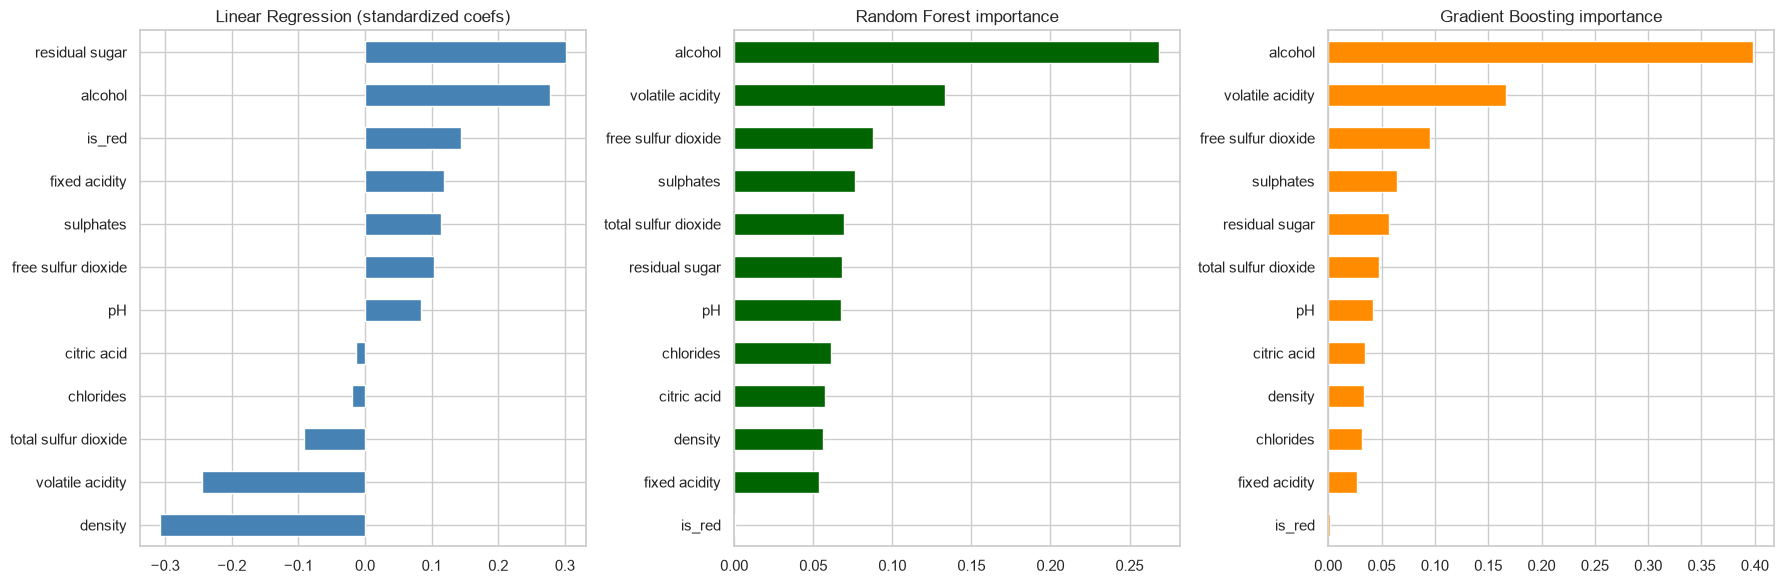

In [64]:
fig, axes = plt.subplots(1, 3, figsize=(18,6))

coefs.sort_values().plot(kind="barh", ax=axes[0], color="steelblue")
axes[0].set_title("Linear Regression (standardized coefs)")

rf_importance.sort_values().plot(kind="barh", ax=axes[1], color="darkgreen")
axes[1].set_title("Random Forest importance")

gb_importance.sort_values().plot(kind="barh", ax=axes[2], color="darkorange")
axes[2].set_title("Gradient Boosting importance")

plt.tight_layout()
plt.show()

У всех моделей топ признаков пересекается: alcohol, volatile acidity, is_red, density. Это совпадает с корреляционным анализом. Линейная регрессия показывает знак влияния, деревья — только важность. Важность признака не доказывает причинность: может быть скрытый фактор (например, сорт винограда), который влияет и на признак, и на качество.

Анализ ошибок: 

In [ ]:
best_name = "Gradient Boosting"
best_pred = gb_pred

errors = y_test - best_pred
abs_errors = np.abs(errors)

plt.figure(figsize=(10,4))
sns.histplot(errors, bins=40, kde=True)
plt.title(f"Распределение ошибок ({best_name})")
plt.xlabel("y_true - y_pred")
plt.show()

errors.describe()

ошибки в основном около нуля, но есть хвосты в обе стороны. Модель ошибается не одинаково на всех объектах — есть вина, где она сильно промахивается.

In [65]:
error_table = X_test.copy()
error_table["y_true"] = y_test
error_table["y_pred"] = best_pred
error_table["abs_error"] = abs_errors

top_errors = error_table.sort_values("abs_error", ascending=False).head(10)
top_errors

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,is_red,y_true,y_pred,abs_error
3649,11.8,0.230,0.38,11.10,0.034,15.0,123.0,0.99970,2.93,0.55,9.7,0,3,5.716879,2.716879
2339,6.9,0.390,0.40,4.60,0.022,5.0,19.0,0.99150,3.31,0.37,12.6,0,3,5.576753,2.576753
3016,8.6,0.550,0.35,15.55,0.057,35.5,366.5,1.00010,3.04,0.63,11.0,0,3,5.528583,2.528583
1374,6.8,0.815,0.00,1.20,0.267,16.0,29.0,0.99471,3.32,0.51,9.8,1,3,5.451043,2.451043
2815,8.2,0.370,0.36,1.00,0.034,17.0,93.0,0.99060,3.04,0.32,11.7,0,8,5.820450,2.179550
3204,7.1,0.260,0.49,2.20,0.032,31.0,113.0,0.99030,3.37,0.42,12.9,0,9,6.927002,2.072998
2753,7.9,0.160,0.30,4.80,0.037,37.0,171.0,0.99670,3.47,0.44,9.0,0,4,6.017707,2.017707
3715,6.8,0.200,0.27,1.20,0.034,19.0,68.0,0.99020,3.14,0.37,11.7,0,4,6.015224,2.015224
45,4.6,0.520,0.15,2.10,0.054,8.0,65.0,0.99340,3.90,0.56,13.1,1,4,6.013062,2.013062
4012,7.1,0.210,0.28,2.70,0.034,23.0,111.0,0.99405,3.35,0.64,10.2,0,4,5.984758,1.984758


Самые большие ошибки — на винах с качеством 3–4 и 8–9. Таких объектов мало в обучении, поэтому модель их плохо выучила. Ещё возможны «странные» вина с необычной комбинацией признаков.

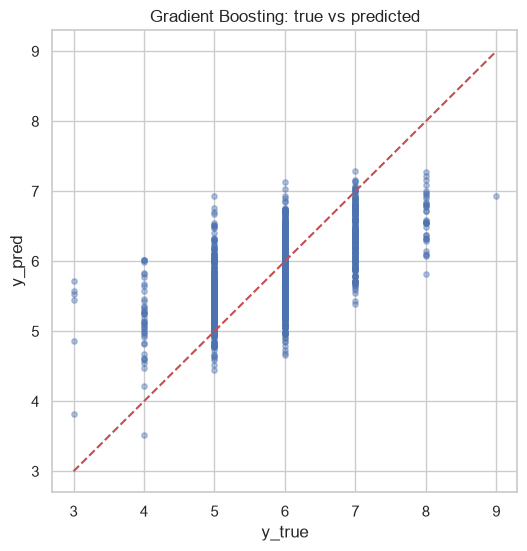

In [66]:
plt.figure(figsize=(6,6))
plt.scatter(y_test, best_pred, alpha=0.4, s=15)
plt.plot([y.min(), y.max()], [y.min(), y.max()], "r--")
plt.xlabel("y_true")
plt.ylabel("y_pred")
plt.title(f"{best_name}: true vs predicted")
plt.show()

модель «стягивает» предсказания к среднему: высокие оценки занижает, низкие завышает

In [ ]:
per_class = pd.DataFrame({
    "y_true": y_test,
    "abs_error": abs_errors
}).groupby("y_true")["abs_error"].agg(["mean", "count"])
per_class.columns = ["mean_abs_error", "count"]
per_class

MAE резко растёт для классов 3, 4, 8, 9 — там мало примеров. Модель плохо предсказывает редкие значения качества. Причины: мало данных по этим классам, MSE «любит» частые классы, деревья редко делают отдельные листья под 1–2 объекта.

Что можно улучшить: стратификация, oversampling редких классов, веса объектов, или переформулировать задачу как классификацию.

ВЫВОД: цель работы достигнута — RMSE < 0.70. Лучшая модель — Random Forest (RMSE ≈ 0.61), они сильно лучше baseline (0.86) и линейной регрессии (0.73). Главные признаки — alcohol и volatile acidity, что совпадает с EDA. Feature importance не доказывает причинность. Основная проблема — редкие классы качества: модель их плохо предсказывает из-за несбалансированности данных. Все random_state зафиксированы, тест использован один раз — эксперимент воспроизводим. 